# Human-Caused Wildfire Ignitions in Four Portuguese Municipalities

## Statistical Analysis Before and After the 2017 Wildfire Crisis

This study examines wildfire ignition records from the Sistema de Gestão de Informação de Incêndios Florestais (SGIF), provided by the Instituto da Conservação da Natureza e das Florestas (ICNF).

It focuses on Braga, Guimarães, Guarda, and Faro between 2001 and 2025. The four municipalities represent different geographic, demographic, and territorial contexts in Portugal.

The analysis asks whether the distribution of human-caused ignitions and the annual number of fire ignitions changed after the 2017 wildfire crisis. It distinguishes between negligent and intentional ignitions and uses both descriptive and inferential statistical methods.

## Research questions

### Main research question

Did the distribution of human-caused fire ignitions and the annual number of fire ignitions change significantly before and after the 2017 wildfire crisis in Braga, Guimarães, Guarda, and Faro?

### Specific research questions

#### RQ1: Proportion of intentional ignitions

Did the proportion of intentional ignitions among human-caused ignitions change significantly between the pre-2017 period (2001–2016) and the post-2017 period (2018–2025)?

**Response variable:** Cause type  
**Grouping variable:** Period  
**Statistical test:** Two-proportion test

#### RQ2: Annual number of ignitions

Did the mean annual number of fire ignitions differ significantly between the pre-2017 and post-2017 periods?

**Response variable:** Annual number of ignitions  
**Grouping variable:** Period  
**Statistical test:** Independent-samples t-test

#### RQ3: Differences between municipalities

Did the mean annual number of fire ignitions differ significantly among Braga, Guimarães, Guarda, and Faro?

**Response variable:** Annual number of ignitions  
**Grouping variable:** Municipality  
**Statistical test:** One-way ANOVA

All hypothesis tests use a significance level of \(\alpha = 0.05\). The year 2017 is treated as a transition year and excluded from the before-and-after comparisons.

## Data and study scope

The dataset contains individual wildfire ignition records from the SGIF/ICNF database. The available files cover the period from 2001 to 2025.

The files are read and combined into a single dataset for the analysis of Braga, Guimarães, Guarda, and Faro. Municipality names are normalized so that differences in spelling and accents do not affect the selection.

### Imports and analysis parameters

Column names are converted to uppercase, which ensures consistent processing across files from different years.

In [19]:
from pathlib import Path
import pandas as pd

DATA_FOLDER = Path("dados")
MUNICIPALITIES = ["BRAGA", "GUIMARAES", "GUARDA", "FARO"]

MUNICIPALITIES_AREA_KM2 = {
    "BRAGA": 183,
    "GUIMARAES": 241,
    "GUARDA": 712,
    "FARO": 203,
}



### Loading and combining the data

The CSV and Excel files are located in the `dados` folder. Each file is read separately, its column names are standardized, and the resulting tables are concatenated into a single dataset.

The output below gives the number of records and the available variables before the study scope is applied.

In [20]:

files = sorted(
    file
    for extension in ("csv",)
    for file in DATA_FOLDER.glob(f"*.{extension}")
)

if not files:
    raise FileNotFoundError(f"No files found in folder '{DATA_FOLDER}'.")

tables = []

for file in files:
    print("Reading:", file)

    if file.suffix.lower() == ".csv":
        table = pd.read_csv(
            file,
            sep=";",
            decimal=",",
            encoding="utf-8-sig",
            low_memory=False
        )
    else:
        table = pd.read_excel(file)

    table.columns = table.columns.astype(str).str.upper().str.strip()
    tables.append(table)

df = pd.concat(tables, ignore_index=True)

print(f"Total records: {len(df)}")
print("Columns:", sorted(list(df.columns)))


Reading: dados\Registos_Incendios_SGIF_2001_2010.csv
Reading: dados\Registos_Incendios_SGIF_2011_2020.csv
Reading: dados\Registos_Incendios_SGIF_2021_2025.csv
Total records: 497478
Columns: ['ANO', 'AREAAGRIC_HA', 'AREAMATO_HA', 'AREAPOV_HA', 'AREATOTAL_HA', 'BUI', 'CLASSEAREA', 'CODCAUSA', 'CODIGO_ANEPC', 'CODIGO_SGIF', 'CONCELHO', 'DATAHORAALERTA', 'DATAHORA_EXTINCAO', 'DATAHORA_PRIMEIRAINTERVENCAO', 'DC', 'DESCRICAOCAUSA', 'DIA', 'DISTRITO', 'DMC', 'DSR', 'DTCCFR', 'DURACAO_HORAS', 'FFMC', 'FONTEALERTA', 'FREGUESIA', 'FWI', 'GRUPOCAUSA', 'HORA', 'INCSUP24HORAS', 'ISI', 'LATITUDE', 'LOCAL', 'LONGITUDE', 'MES', 'RNAP', 'RNMPF', 'TIPOCAUSA', 'X_ETRS89', 'X_MILITAR', 'Y_ETRS89', 'Y_MILITAR']


### Defining the study population

Municipality names are converted to uppercase, whitespace is removed, and accented characters are normalized. The resulting identifier is used to select the four municipalities included in the study.

The dataset is then restricted to Braga, Guimarães, Guarda, and Faro.

In [21]:
# Standardize municipality names by converting to uppercase, trimming spaces,
# and removing accents/special characters to create a consistent matching key.
df["MUNICIPALITY"] = (
    df["CONCELHO"].astype(str).str.upper().str.strip()
    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii")
)

# Identify the municipality whose normalized versions
# match the reference municipality scope and display each unique matches.
matching_spellings = df.loc[
    df["MUNICIPALITY"].isin(MUNICIPALITIES),
    "CONCELHO"
].unique()
print("Matching spellings:", matching_spellings)


# Filter records belonging to the municipalities scope
# and create an independent copy of the resulting subset.
scoped_data = df[df["MUNICIPALITY"].isin(MUNICIPALITIES)].copy()
print(f"Records in scope: {len(scoped_data)}")


Matching spellings: <StringArray>
['Guimarães', 'Guarda', 'Braga', 'Faro']
Length: 4, dtype: str
Records in scope: 15534


### Defining the analysis year

For each ignition, the analysis year is taken from the alert date whenever possible. If the alert date is unavailable or cannot be used, the original `ANO` variable provides the year.

This common year variable is used to define the periods for the statistical comparisons.

In [22]:
# Create a unified year variable from the alert date when available;
# otherwise, use the existing year column.
if "DATAHORAALERTA" in scoped_data.columns:
    scoped_data["ANALYSIS_YEAR"] = pd.to_datetime(
        scoped_data["DATAHORAALERTA"], errors="coerce", dayfirst=True
    ).dt.year
else:
    scoped_data["ANALYSIS_YEAR"] = scoped_data["ANO"]


# Preview the municipality and analysis year fields.
scoped_data[
    [
        "MUNICIPALITY",
        "ANALYSIS_YEAR"
    ]
].head() #.head() #.tail()

,MUNICIPALITY,ANALYSIS_YEAR
104,GUIMARAES,2001
117,GUIMARAES,2001
127,GUIMARAES,2001
128,GUARDA,2001
165,GUIMARAES,2001


### Normalizing ignition causes

Cause values are converted to uppercase. In the SGIF data, an empty cause field means the fire was **not investigated**, while `DESCONHECIDA` means it was investigated but the cause could not be determined.

Since the research questions focus only on human-caused ignitions (negligent vs. intentional), both situations are grouped into a single category, `DESCONHECIDA`, and flagged with `MISSING_CAUSE`. These records are excluded from the cause comparison but kept in the dataset and reported, because removing them silently could bias the analysis.

In [23]:
# Clean and standardize cause descriptions, flag missing values,
# and assign a default label to records without cause information.
cause = (
    scoped_data["TIPOCAUSA"].astype(str).str.strip()
    .replace({"": None, "nan": None, "None": None})
)
scoped_data["CAUSE"] = cause.fillna("DESCONHECIDA").str.upper()
scoped_data["MISSING_CAUSE"] = scoped_data["CAUSE"].eq("DESCONHECIDA")

# Preview the original, normalized, and missing-cause indicators.
scoped_data[
    [
        "TIPOCAUSA",
        "CAUSE",
        "MISSING_CAUSE"
    ]
].head()

,TIPOCAUSA,CAUSE,MISSING_CAUSE
104,NaN,DESCONHECIDA,True
117,NaN,DESCONHECIDA,True
127,NaN,DESCONHECIDA,True
128,NaN,DESCONHECIDA,True
165,NaN,DESCONHECIDA,True


### Creating derived variables

The analysis uses two derived variables:

- `INTERVENTION_TIME_MINUTES`: time between the alert and the first intervention;
- `PERIOD`: temporal classification of each record.

| Period | Years | Role in the analysis |
|---|---:|---|
| Pre-2017 | 2001–2016 | Before the wildfire crisis |
| 2017 | 2017 | Transition year, excluded from comparisons |
| Post-2017 | 2018–2025 | After the wildfire crisis |

Ignition density is calculated from the area of each municipality so that comparisons account for differences in municipality size.

In [24]:
alert_time = pd.to_datetime(scoped_data["DATAHORAALERTA"], errors="coerce", dayfirst=True)
intervention_time = pd.to_datetime(
    scoped_data["DATAHORA_PRIMEIRAINTERVENCAO"], errors="coerce", dayfirst=True
)
scoped_data["INTERVENTION_TIME_MINUTES"] = (intervention_time - alert_time).dt.total_seconds() / 60

scoped_data["PERIOD"] = pd.cut(
    scoped_data["ANALYSIS_YEAR"], bins=[2000, 2016, 2017, 2025],
    labels=["2001-2016", "2017", "2018-2025"]
)

scoped_data[["ANALYSIS_YEAR", "INTERVENTION_TIME_MINUTES", "PERIOD"]].head()

,ANALYSIS_YEAR,INTERVENTION_TIME_MINUTES,PERIOD
104,2001,NaN,2001-2016
117,2001,NaN,2001-2016
127,2001,NaN,2001-2016
128,2001,NaN,2001-2016
165,2001,NaN,2001-2016


In [25]:
# Calculate the ignition density for a given scope of data.
# This function takes a DataFrame of ignition data and calculates
# the density of ignitions per square kilometer per year for each municipality.
def calculate_ignition_density(
    data,
    start_year=None,
    end_year=None,
    municipalities=MUNICIPALITIES,
    area_by_municipality=MUNICIPALITIES_AREA_KM2,
    year_column="ANALYSIS_YEAR",
):
    scoped = data.copy()

    if start_year is not None:
        scoped = scoped[scoped[year_column] >= start_year]

    if end_year is not None:
        scoped = scoped[scoped[year_column] <= end_year]

    years_in_scope = scoped[year_column].dropna().nunique()

    if years_in_scope == 0:
        raise ValueError("The selected scope contains no valid years.")

    result = (
        scoped.groupby("MUNICIPALITY")
        .size()
        .rename("IGNITIONS")
        .reindex(municipalities, fill_value=0)
        .to_frame()
    )

    result["AREA_KM2"] = result.index.map(area_by_municipality)
    result["YEARS"] = years_in_scope
    result["IGNITION_DENSITY_IGNITIONS_KM2_YEAR"] = (
        result["IGNITIONS"]
        / result["AREA_KM2"]
        / result["YEARS"]
    )

    return result.reset_index()

In [26]:
# All years
ignition_density = calculate_ignition_density(scoped_data)
display(ignition_density)

,MUNICIPALITY,IGNITIONS,AREA_KM2,YEARS,IGNITION_DENSITY_IGNITIONS_KM2_YEAR
0,BRAGA,4279,183,25,0.935301
1,GUIMARAES,8641,241,25,1.434191
2,GUARDA,1806,712,25,0.101461
3,FARO,808,203,25,0.159212


In [27]:
required_columns = [
    "MUNICIPALITY",                  # normalized municipality name
    "PERIOD",                        # period category based on analysis year
    "ANALYSIS_YEAR",                 # analysis year
    "DATAHORAALERTA",                # alert date and time
    "DATAHORA_PRIMEIRAINTERVENCAO",  # first intervention date and time
    "DATAHORA_EXTINCAO",             # extinction date and time
    "CAUSE",                         # normalized cause description
    "MISSING_CAUSE",                 # no cause attributed (empty or unknown)
    "AREATOTAL_HA",                  # total burned area in hectares
    "INTERVENTION_TIME_MINUTES",     # time to first intervention (minutes)
    "DURACAO_HORAS",                 # fire duration in hours
]

missing_columns = [
    column for column in required_columns
    if column not in scoped_data.columns
]

if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")

scoped_data = scoped_data[required_columns].copy()

print(f"Filtered data shape: {scoped_data.shape}")
display(scoped_data.head())

Filtered data shape: (15534, 11)


,MUNICIPALITY,PERIOD,ANALYSIS_YEAR,DATAHORAALERTA,DATAHORA_PRIMEIRAINTERVENCAO,DATAHORA_EXTINCAO,CAUSE,MISSING_CAUSE,AREATOTAL_HA,INTERVENTION_TIME_MINUTES,DURACAO_HORAS
104,GUIMARAES,2001-2016,2001,18/02/2001 22:31,NaN,18/02/2001 23:32,DESCONHECIDA,True,0.10,NaN,1.016667
117,GUIMARAES,2001-2016,2001,19/02/2001 14:48,NaN,19/02/2001 16:05,DESCONHECIDA,True,0.20,NaN,1.283333
127,GUIMARAES,2001-2016,2001,19/02/2001 17:53,NaN,19/02/2001 18:45,DESCONHECIDA,True,3.00,NaN,0.866667
128,GUARDA,2001-2016,2001,19/02/2001 17:55,NaN,19/02/2001 18:40,DESCONHECIDA,True,1.00,NaN,0.750000
165,GUIMARAES,2001-2016,2001,20/02/2001 17:33,NaN,20/02/2001 18:30,DESCONHECIDA,True,0.15,NaN,0.950000


In [28]:
# # Uncomment the following lines to save the scoped data to a CSV file.
# output_file =  "scoped_data_required_columns.csv"

# scoped_data.to_csv(
#    output_file,
#    index=False,
#    encoding="utf-8-sig"
# )

# print(f"Saved {len(scoped_data):,} records to: {output_file}")

## Data quality and descriptive verification

The tables below check the structure and quality of the scoped dataset. They include annual ignition counts, cause categories, missing-cause percentages, missing quantitative values, intervention times, and the contingency table used to compare negligent and intentional ignitions.

These checks are carried out before the inferential statistical analysis.

In [29]:
print("1) Records by year and municipality")
display(pd.crosstab(scoped_data["ANALYSIS_YEAR"], scoped_data["MUNICIPALITY"]))

1) Records by year and municipality


MUNICIPALITY,BRAGA,FARO,GUARDA,GUIMARAES
ANALYSIS_YEAR,,,,
2001,285,16,159,833
2002,279,15,154,795
2003,381,14,122,950
2004,253,27,74,593
2005,406,29,137,876
2006,330,69,102,434
2007,216,80,84,383
2008,83,42,142,170
2009,242,61,109,487


In [30]:
print("2) Cause type by municipality")
display(pd.crosstab(scoped_data["CAUSE"], scoped_data["MUNICIPALITY"]))


2) Cause type by municipality


MUNICIPALITY,BRAGA,FARO,GUARDA,GUIMARAES
CAUSE,,,,
DESCONHECIDA,3687,513,823,7910
INTENCIONAL,146,42,230,202
NATURAL,0,0,50,0
NEGLIGENTE,168,248,635,369
REACENDIMENTO,278,5,68,160


In [31]:
print("3) % of records without a cause, by year and municipality")
display((pd.crosstab(
    scoped_data["ANALYSIS_YEAR"], scoped_data["MUNICIPALITY"], values=scoped_data["MISSING_CAUSE"], aggfunc="mean"
) * 100).round(1))


3) % of records without a cause, by year and municipality


MUNICIPALITY,BRAGA,FARO,GUARDA,GUIMARAES
ANALYSIS_YEAR,,,,
2001,98.9,100.0,100.0,99.9
2002,98.9,73.3,90.3,99.9
2003,99.2,100.0,89.3,99.8
2004,99.6,88.9,89.2,99.5
2005,97.5,100.0,94.9,99.2
2006,99.7,98.6,83.3,99.8
2007,90.7,96.2,48.8,98.4
2008,98.8,90.5,25.4,96.5
2009,87.6,95.1,12.8,98.8


In [32]:
columns = [
    "AREATOTAL_HA", "DATAHORAALERTA",
    "DATAHORA_PRIMEIRAINTERVENCAO", "DATAHORA_EXTINCAO", "DURACAO_HORAS",
]
columns = [column for column in columns if column in scoped_data.columns]

print("4) % missing by year")
display((scoped_data.groupby("ANALYSIS_YEAR")[columns].apply(lambda x: x.isna().mean()) * 100).round(1))


4) % missing by year


,AREATOTAL_HA,DATAHORAALERTA,DATAHORA_PRIMEIRAINTERVENCAO,DATAHORA_EXTINCAO,DURACAO_HORAS
ANALYSIS_YEAR,,,,,
2001,0.0,0.0,100.0,0.0,0.0
2002,0.0,0.0,100.0,0.0,0.0
2003,0.0,0.0,100.0,0.0,0.0
2004,0.0,0.0,100.0,0.0,0.0
2005,0.0,0.0,100.0,0.0,0.0
2006,0.0,0.0,100.0,0.0,0.0
2007,0.0,0.0,100.0,0.0,0.0
2008,0.0,0.0,17.8,0.0,0.0
2009,0.0,0.0,12.3,0.0,0.0


In [33]:
print("5) Time to first intervention (minutes)")
display(scoped_data.groupby("MUNICIPALITY")["INTERVENTION_TIME_MINUTES"].describe().round(1))
print("Negative:", int((scoped_data["INTERVENTION_TIME_MINUTES"] < 0).sum()),
      "| Above 24h:", int((scoped_data["INTERVENTION_TIME_MINUTES"] > 1440).sum()))


5) Time to first intervention (minutes)


,count,mean,std,min,25%,50%,75%,max
MUNICIPALITY,,,,,,,,
BRAGA,2068.0,12.1,7.8,0.0,8.0,11.0,15.0,139.0
FARO,550.0,10.4,5.0,1.0,7.0,10.0,12.0,42.0
GUARDA,915.0,16.2,15.8,0.0,9.0,13.0,20.0,265.0
GUIMARAES,3671.0,12.1,13.4,0.0,7.0,10.0,15.0,615.0


Negative: 0 | Above 24h: 0


In [34]:

hypothesis_data = scoped_data[
    scoped_data["CAUSE"].str.lower().isin(["negligente", "intencional"])
    & (scoped_data["PERIOD"] != "2017")
]
print("6) Negligent vs intentional by period (2017 excluded)")
display(pd.crosstab([hypothesis_data["MUNICIPALITY"], hypothesis_data["PERIOD"]], hypothesis_data["CAUSE"]))


6) Negligent vs intentional by period (2017 excluded)


CAUSE                   INTENCIONAL  NEGLIGENTE
MUNICIPALITY PERIOD                            
BRAGA        2001-2016           60         113
             2018-2025           85          48
FARO         2001-2016            9         113
             2018-2025           33         117
GUARDA       2001-2016          137         454
             2018-2025           66         147
GUIMARAES    2001-2016           35         145
             2018-2025          167         221

## Summary of the data preparation stage

The prepared dataset contains:

- Records from the four selected municipalities;
- A standardized analysis year;
- A categorical period variable;
- Normalized ignition-cause categories;
- An indicator for missing cause information;
- Annual ignition counts;
- Ignition density by municipality;
- Intervention-time measurements.

These variables provide the basis for the exploratory analysis and for testing the three research questions defined above.

## Exploratory analysis

This section describes the main patterns in the scoped data before the inferential tests are applied. It compares annual ignition activity across municipalities and examines how the composition of human-caused ignitions differs between the pre-2017 and post-2017 periods. The year 2017 remains visible in the annual trend but is excluded from the before-and-after cause comparison.

,count,mean,std,min,25%,50%,75%,max
MUNICIPALITY,,,,,,,,
BRAGA,25.0,171.2,117.0,36.0,70.0,154.0,253.0,406.0
GUIMARAES,25.0,345.6,277.0,54.0,117.0,276.0,487.0,950.0
GUARDA,25.0,72.2,43.2,23.0,43.0,58.0,102.0,159.0
FARO,25.0,32.3,16.8,14.0,22.0,29.0,35.0,80.0


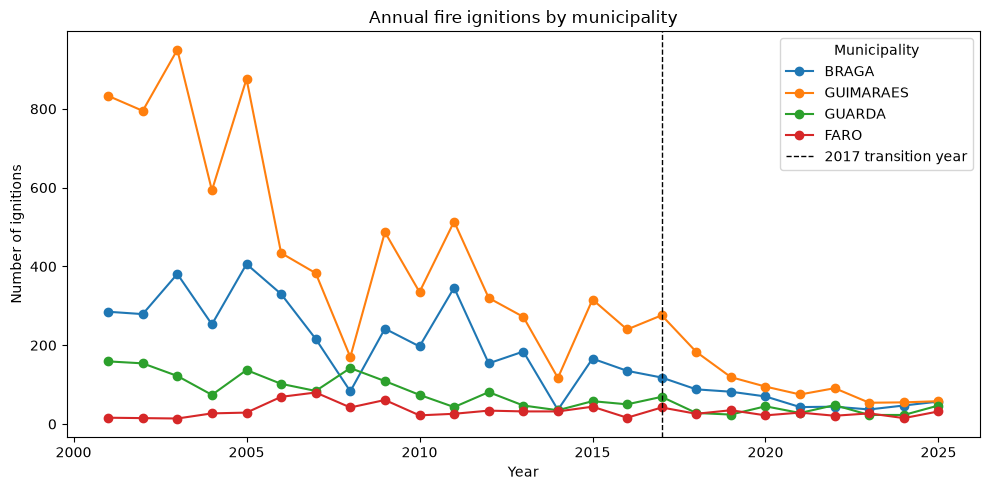

In [36]:
import matplotlib.pyplot as plt

annual_counts = (
    scoped_data.groupby(["ANALYSIS_YEAR", "MUNICIPALITY"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=MUNICIPALITIES)
)

display(annual_counts.describe().T.round(1))

ax = annual_counts.plot(figsize=(10, 5), marker="o")
ax.axvline(2017, color="black", linestyle="--", linewidth=1, label="2017 transition year")
ax.set(title="Annual fire ignitions by municipality", xlabel="Year", ylabel="Number of ignitions")
ax.legend(title="Municipality")
plt.tight_layout()
plt.show()

In [37]:
period_counts = (
    annual_counts.rename_axis("Year")
    .reset_index()
    .assign(PERIOD=lambda table: table["Year"].map(
        lambda year: "Pre-2017" if year < 2017 else "2017" if year == 2017 else "Post-2017"
    ))
    .query('PERIOD != "2017"')
    .groupby("PERIOD")[MUNICIPALITIES]
    .agg(["mean", "std"])
    .round(1)
)

display(period_counts)

human_caused = scoped_data[
    scoped_data["CAUSE"].str.lower().isin(["negligente", "intencional"])
    & (scoped_data["PERIOD"] != "2017")
].copy()
cause_share = pd.crosstab(
    [human_caused["MUNICIPALITY"], human_caused["PERIOD"]],
    human_caused["CAUSE"],
    normalize="index",
).mul(100).round(1)
display(cause_share)


MUNICIPALITY  BRAGA        GUIMARAES        GUARDA        FARO      
               mean    std      mean    std   mean   std  mean   std
PERIOD                                                              
Post-2017      58.5   19.3      91.2   43.5   33.2  11.3  25.9   6.4
Pre-2017      230.8  104.8     477.2  261.9   91.9  41.3  34.9  19.9

CAUSE                   INTENCIONAL  NEGLIGENTE
MUNICIPALITY PERIOD                            
BRAGA        2001-2016         34.7        65.3
             2018-2025         63.9        36.1
FARO         2001-2016          7.4        92.6
             2018-2025         22.0        78.0
GUARDA       2001-2016         23.2        76.8
             2018-2025         31.0        69.0
GUIMARAES    2001-2016         19.4        80.6
             2018-2025         43.0        57.0